In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Pandas: 2.2.3
NumPy: 2.3.5


In [3]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# Count values that are actually blank or whitespace in TotalCharges
blank_charges = df["TotalCharges"].str.strip().eq("").sum()

print("Blank TotalCharges entries:", blank_charges)

Blank TotalCharges entries: 11


In [8]:
df.loc[
    df["TotalCharges"].str.strip().eq(""),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [9]:
for column in df.columns:
    print(f"{column:20} {df[column].dtype}")

customerID           object
gender               object
SeniorCitizen        int64
Partner              object
Dependents           object
tenure               int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges       float64
TotalCharges         object
Churn                object


In [10]:
df.nunique().sort_values()

Churn                  2
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
PaperlessBilling       2
PhoneService           2
Contract               3
StreamingMovies        3
StreamingTV            3
TechSupport            3
OnlineBackup           3
OnlineSecurity         3
InternetService        3
MultipleLines          3
DeviceProtection       3
PaymentMethod          4
tenure                73
MonthlyCharges      1585
TotalCharges        6531
customerID          7043
dtype: int64

In [11]:
print(df["Churn"].unique())
print(df["Churn"].value_counts())

['No' 'Yes']
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [12]:
df.select_dtypes(include=["int64", "float64"]).columns.tolist()

['SeniorCitizen', 'tenure', 'MonthlyCharges']

In [13]:
print(df["TotalCharges"].head(10).tolist())

['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.05', '3487.95']


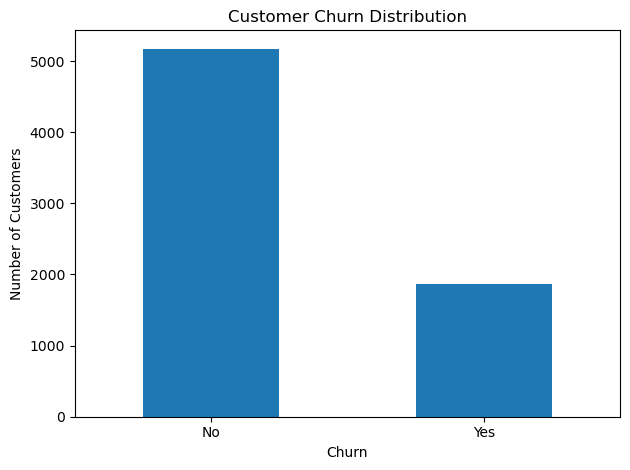

In [14]:
churn_counts = df["Churn"].value_counts().reindex(["No", "Yes"])
churn_counts.plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [15]:
df["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [16]:
churn_by_contract = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

churn_by_contract

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


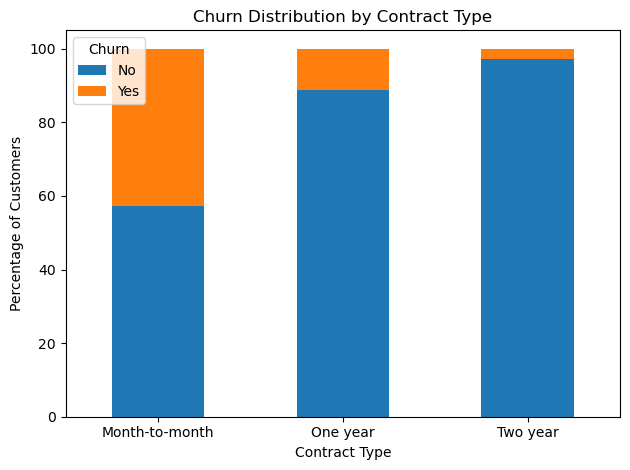

In [17]:
churn_by_contract.plot(kind="bar", stacked=True)

plt.title("Churn Distribution by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
churn_by_tenure = pd.crosstab(
    pd.cut(df["tenure"], bins=[0, 12, 24, 48, 72],
           labels=["1–12 months", "13–24 months",
                   "25–48 months", "49–72 months"]),
    df["Churn"],
    normalize="index"
) * 100

churn_by_tenure

Churn,No,Yes
tenure,,
1–12 months,52.321839,47.678161
13–24 months,71.289062,28.710938
25–48 months,79.611041,20.388959
49–72 months,90.486824,9.513176


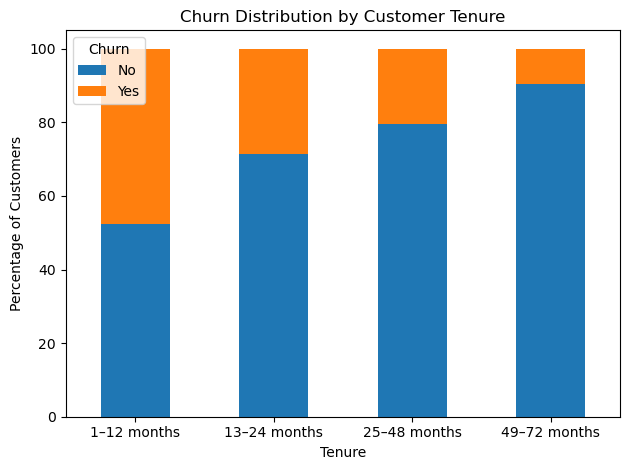

In [19]:
churn_by_tenure.plot(kind="bar", stacked=True)

plt.title("Churn Distribution by Customer Tenure")
plt.xlabel("Tenure")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [20]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].str.strip(),
    errors="coerce"
)

print("TotalCharges dtype:", df["TotalCharges"].dtype)
print("Missing values in TotalCharges:", df["TotalCharges"].isna().sum())

TotalCharges dtype: float64
Missing values in TotalCharges: 11


In [21]:
df.loc[df["TotalCharges"].isna(), "TotalCharges"] = 0

In [22]:
print("Missing values remaining:", df["TotalCharges"].isna().sum())
print("Dataset shape:", df.shape)
print("TotalCharges dtype:", df["TotalCharges"].dtype)

Missing values remaining: 0
Dataset shape: (7043, 21)
TotalCharges dtype: float64


In [23]:
missing = df.isna().sum()

print(missing[missing > 0])

Series([], dtype: int64)


In [24]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

In [25]:
# Separate the input features from the target
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

X.head()

Features shape: (7043, 19)
Target shape: (7043,)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)


In [27]:
print("Training churn distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting churn distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training churn distribution:
Churn
No     73.464679
Yes    26.535321
Name: proportion, dtype: float64

Testing churn distribution:
Churn
No     73.456352
Yes    26.543648
Name: proportion, dtype: float64


In [28]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Number of numerical features:", len(numeric_features))

print("\nCategorical features:", categorical_features)
print("Number of categorical features:", len(categorical_features))

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Number of numerical features: 4

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Number of categorical features: 15


In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessor created successfully!")


Preprocessor created successfully!


In [30]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

Original training shape: (5634, 19)
Processed training shape: (5634, 45)
Original testing shape: (1409, 19)
Processed testing shape: (1409, 45)


In [31]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter = 1000)
model.fit(X_train_processed , y_train)
print("Model trained successfully!")

Model trained successfully!


In [32]:
y_pred = model.predict(X_test_processed)
print("First 10 actual labels:")
print(y_test.head(10).tolist())

print("First 10 predicted labels:")
print(y_pred[:10])

First 10 actual labels:
['No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes']
First 10 predicted labels:
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No']


In [33]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Test Accuracy: 80.55 %

Classification Report:
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



[[926 109]
 [165 209]]


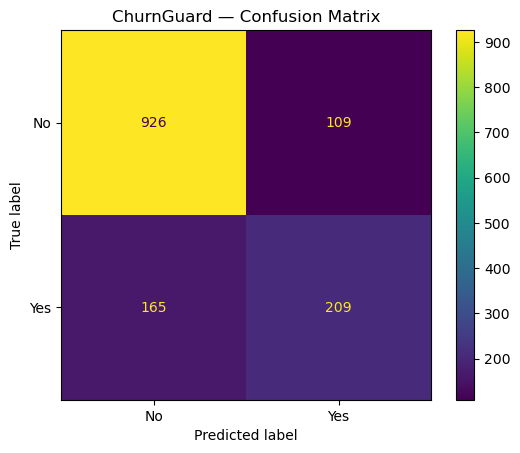

In [34]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["No", "Yes"]
)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

disp.plot()
plt.title("ChurnGuard — Confusion Matrix")
plt.show()

In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Probability of churn ("Yes")
churn_probabilities = model.predict_proba(X_test_processed)[
    :, list(model.classes_).index("Yes")
]

for threshold in [0.5, 0.4, 0.3]:
    y_threshold_pred = np.where(
        churn_probabilities >= threshold,
        "Yes",
        "No"
    )

    print(f"\nThreshold: {threshold}")
    print("Accuracy:", round(accuracy_score(y_test, y_threshold_pred), 3))
    print("Precision:", round(precision_score(
        y_test, y_threshold_pred, pos_label="Yes"
    ), 3))
    print("Recall:", round(recall_score(
        y_test, y_threshold_pred, pos_label="Yes"
    ), 3))
    print("F1-score:", round(f1_score(
        y_test, y_threshold_pred, pos_label="Yes"
    ), 3))


Threshold: 0.5
Accuracy: 0.806
Precision: 0.657
Recall: 0.559
F1-score: 0.604

Threshold: 0.4
Accuracy: 0.777
Precision: 0.568
Recall: 0.668
F1-score: 0.614

Threshold: 0.3
Accuracy: 0.749
Precision: 0.519
Recall: 0.754
F1-score: 0.615


In [36]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [37]:
from sklearn.metrics import accuracy_score, classification_report

rf_pred = rf_model.predict(X_test_processed)

print("Random Forest Accuracy:",
      round(accuracy_score(y_test, rf_pred) * 100, 2), "%")

print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 77.86 %
              precision    recall  f1-score   support

          No       0.82      0.89      0.85      1035
         Yes       0.60      0.48      0.53       374

    accuracy                           0.78      1409
   macro avg       0.71      0.68      0.69      1409
weighted avg       0.77      0.78      0.77      1409



In [38]:
from sklearn.metrics import precision_score, recall_score, f1_score

results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Churn Precision": precision_score(y_test, y_pred, pos_label="Yes"),
        "Churn Recall": recall_score(y_test, y_pred, pos_label="Yes"),
        "Churn F1": f1_score(y_test, y_pred, pos_label="Yes")
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Churn Precision": precision_score(y_test, rf_pred, pos_label="Yes"),
        "Churn Recall": recall_score(y_test, rf_pred, pos_label="Yes"),
        "Churn F1": f1_score(y_test, rf_pred, pos_label="Yes")
    }
])

results.round(3)

,Model,Accuracy,Churn Precision,Churn Recall,Churn F1
0,Logistic Regression,0.806,0.657,0.559,0.604
1,Random Forest,0.779,0.605,0.479,0.534


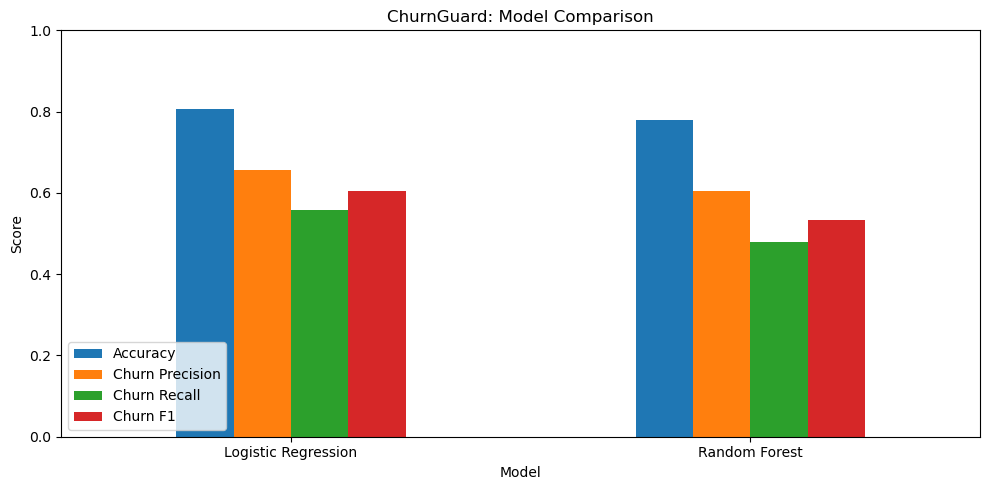

In [39]:
results.set_index("Model")[
    ["Accuracy", "Churn Precision", "Churn Recall", "Churn F1"]
].plot(kind="bar", figsize=(10, 5))

plt.title("ChurnGuard: Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

In [40]:
feature_names = preprocessor.get_feature_names_out()

coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": model.coef_[0]
})

coefficients["Absolute_Coefficient"] = (
    coefficients["Coefficient"].abs()
)

coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
).head(15)

,Feature,Coefficient,Absolute_Coefficient
1,num__tenure,-1.257539,1.257539
38,cat__Contract_Two year,-0.776594,0.776594
15,cat__InternetService_DSL,-0.648646,0.648646
16,cat__InternetService_Fiber optic,0.634195,0.634195
2,num__MonthlyCharges,-0.591863,0.591863
36,cat__Contract_Month-to-month,0.582883,0.582883
3,num__TotalCharges,0.536253,0.536253
39,cat__PaperlessBilling_No,-0.343227,0.343227
22,cat__OnlineBackup_No internet service,-0.300104,0.300104
17,cat__InternetService_No,-0.300104,0.300104


In [44]:
coefficients = model.coef_[0]

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

feature_importance['Abs_Coefficient'] = (
    feature_importance['Coefficient'].abs()
)

feature_importance = feature_importance.sort_values(
    by='Abs_Coefficient',
    ascending=False
)

feature_importance.head(15)

,Feature,Coefficient,Abs_Coefficient
1,num__tenure,-1.257539,1.257539
38,cat__Contract_Two year,-0.776594,0.776594
15,cat__InternetService_DSL,-0.648646,0.648646
16,cat__InternetService_Fiber optic,0.634195,0.634195
2,num__MonthlyCharges,-0.591863,0.591863
36,cat__Contract_Month-to-month,0.582883,0.582883
3,num__TotalCharges,0.536253,0.536253
39,cat__PaperlessBilling_No,-0.343227,0.343227
22,cat__OnlineBackup_No internet service,-0.300104,0.300104
17,cat__InternetService_No,-0.300104,0.300104


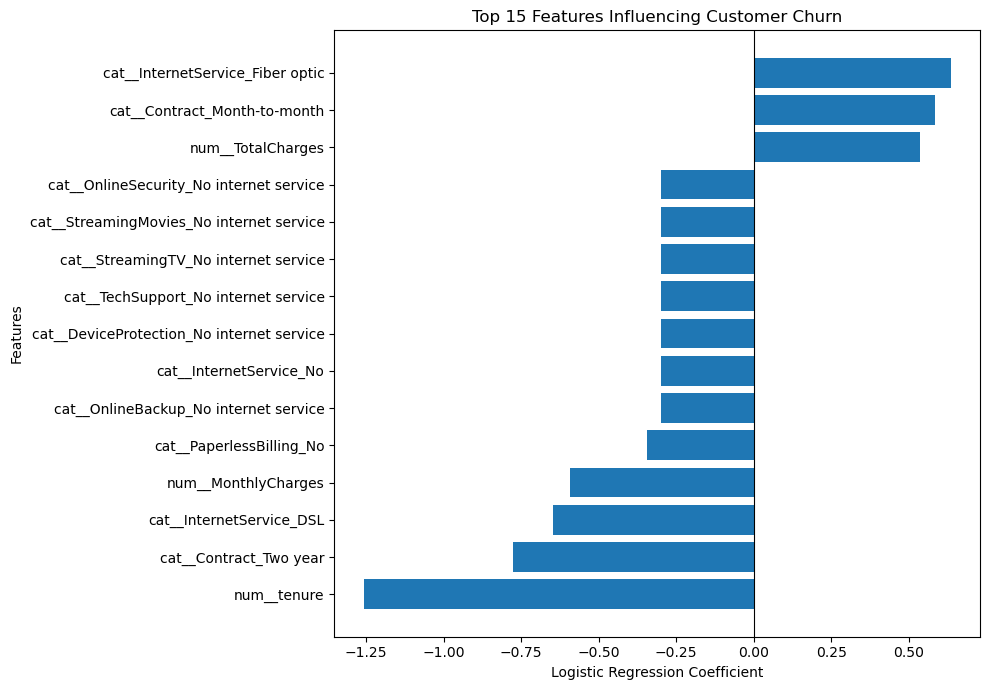

In [45]:
top_features = feature_importance.head(15).sort_values(
    by='Coefficient'
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Coefficient']
)

plt.axvline(x=0, color='black', linewidth=0.8)

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Features")
plt.title("Top 15 Features Influencing Customer Churn")

plt.tight_layout()
plt.show()

In [46]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    average_precision_score
)

# Predict churn probabilities
y_prob = model.predict_proba(X_test_processed)[:, 1]

# Select threshold
final_threshold = 0.3

# Generate predictions
y_final_pred = np.where(y_prob >= final_threshold, "Yes", "No")

# Evaluation
print("Threshold:", final_threshold)

print("\nClassification Report:")
print(classification_report(y_test, y_final_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_final_pred))

print("\nAccuracy:", accuracy_score(y_test, y_final_pred))

# Convert actual labels to binary
y_test_binary = (y_test == "Yes").astype(int)

print("\nROC-AUC:", roc_auc_score(y_test_binary, y_prob))

print("PR-AUC:", average_precision_score(y_test_binary, y_prob))

Threshold: 0.3

Classification Report:
              precision    recall  f1-score   support

          No       0.89      0.75      0.81      1035
         Yes       0.52      0.75      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.79      0.75      0.76      1409


Confusion Matrix:
[[774 261]
 [ 92 282]]

Accuracy: 0.7494677075940384

ROC-AUC: 0.8421349040274871
PR-AUC: 0.6343385058492537


In [47]:
import joblib
from sklearn.pipeline import Pipeline

# Combine the already-fitted preprocessor and model
churn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', model)
])

# Save pipeline and selected threshold
model_bundle = {
    'pipeline': churn_pipeline,
    'threshold': final_threshold
}

joblib.dump(model_bundle, 'churnguard_model.joblib')

print("ChurnGuard model saved successfully!")

ChurnGuard model saved successfully!


In [48]:
loaded_bundle = joblib.load('churnguard_model.joblib')

loaded_pipeline = loaded_bundle['pipeline']
threshold = loaded_bundle['threshold']

# Take one customer from the original test dataset
sample = X_test.iloc[[0]]

# Predict churn probability
probabilities = loaded_pipeline.predict_proba(sample)[0]

yes_index = list(loaded_pipeline.classes_).index('Yes')
churn_probability = probabilities[yes_index]

prediction = (
    'Yes' if churn_probability >= threshold else 'No'
)

print("Churn Probability:", round(churn_probability * 100, 2), "%")
print("Churn Prediction:", prediction)

Churn Probability: 4.59 %
Churn Prediction: No
